# Layer sweep (B): the function CAV and the P gate at every layer, Kircher — HyenaDNA and GENA-LM

Meeting 2026-11-17: run the gate at other layers and compare only the global metric, as a line over depth, to see
whether the middle layers are best. So far each model's function CAV was fitted at **one** layer (NT-v2 500M L24,
HyenaDNA L3, DNABERT-2 L4, GENA-LM L11). Here the same CAVs are fitted at many layers of four models (NT 2.5B and Evo 2
left out for now), and the P gate is scored on the Kircher regions at each layer.

**What is the same as before:** the ChIP sites (`fcav_pool/sites/`), the readout and the L2-logistic estimator (code
copied unchanged from `Pooled Regions 1c`); the motifbreakR calls and the gate (code copied unchanged from `P Gate with
Five Models`, cells 2.1–2.2).

**One change, for speed: each CAV is fitted once on all of its ChIP sites**, with the penalty chosen by 3-fold CV on
those sites, and then applied to the Kircher hits. Before, every TF was also fitted in 5 outer folds, and a hit's
P(bound) was the average of the 5 fold models. The Kircher hits were never in training (every window overlapping an
MPRA region is excluded), so the outer folds were only needed for an honest ChIP AUC. Dropping them cuts the fitting
cost about five-fold (4 instead of 21 regularisation paths per TF). The ChIP AUC reported here comes from the 3-fold
CV used to pick the penalty (slightly optimistic, since the penalty is chosen on the same folds); it is used for the
AUC curve and the AUC ≥ 0.75 tier. P(bound) of the hits = this single fit (as in the Malinois notebooks); the gate only
uses its rank within each TF.

**Optional: the same number of sites for every TF.** The number of matched pairs differs a lot between TFs (at most
2000, at least 50). Section 0 shows how many TFs would remain at a fixed number. If `N_FIX` is set in 1.1, every TF is
fitted a second time on exactly `N_FIX` pairs, the same pairs for every model; TFs with fewer pairs are left out of that
version. This costs one more fit per TF, not another forward pass.

**Two notebooks.** This one fits **HyenaDNA and GENA-LM**; `Layer Sweep A` fits the other two
models. Both write to the same folders. Section 2 scores every model whose fits it finds, so run it (in either
notebook) once all four models are done; a model that is only partly fitted would be scored on fewer TFs.

**Run order**
1. Section 0 (seconds, any runtime): site counts.
2. Section 1 on a **GPU** runtime, one model per session if needed (`MODELS` in 1.1). Resumable per (model, TF).
3. Section 2 on a **CPU** runtime: Kircher gate per layer, line plots.

Output: `fcav_pool/fits_layers/<version>/<model>/<TF>.npz` (version `all`, and `n<N_FIX>` if set), and
`layer_sweep/` (tables and figures).

In [1]:
!pip install -q -U "transformers==4.57.6" "tokenizers==0.22.0" "huggingface_hub==0.34.0" "safetensors==0.4.5"
!pip install -q scikit-learn scipy pandas matplotlib
from google.colab import drive
drive.mount("/content/drive")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.34.0 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.34.0 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.34.0 which is incompatible.
diffusers 0.42.1 requires safetensors>=0.8.0, but you have safetensors 0.4.5 which is incompatible.
Mounted at /content/drive


---
# Section 0 — how many matched pairs each TF has

A TF's pairs: bound sites (best motif hit at the summit of a strong ChIP peak, HepG2 or K562) matched one to one with
unbound sites (same motif, in DNase, ≥ 1 kb from every peak of the TF) inside 5 × 5 × 5 bins of PWM score, GC and CpG
o/e, capped at 2000 pairs; TFs with fewer than 50 pairs have no CAV. Below: the distribution, and for candidate fixed
numbers how many TFs and Kircher hits remain.

In [2]:
WORK_DIR = "/content/drive/MyDrive/GitHub/Biological-Foundation-Model/Notebooks/EP Pair Evaluation/per_occurrence/motif_token_study"
import os, json
import numpy as np, pandas as pd

POOL = f"{WORK_DIR}/fcav_pool"
MWJ = json.load(open(f"{POOL}/mpra_windows.json"))
BUILT = sorted(m for m, s in MWJ["status"].items() if s == "built")
HK_REGIONS = {int(r) for r, v in MWJ["regions"].items() if set(v["cell"].split(",")) <= {"HepG2", "K562"}}
NPAIR, POOLB, POOLU, CELLMIX = {}, {}, {}, {}
for m in BUILT:
    J = json.load(open(f"{POOL}/sites/{m}.json"))
    R = J["records"]
    NPAIR[m] = len(R) // 2
    POOLB[m], POOLU[m] = J.get("pool_bound", np.nan), J.get("pool_unbound", np.nan)
    CELLMIX[m] = "+".join(sorted({r.get("cell", "?") for r in R if r["cls"] == 1}))
S = pd.DataFrame({"pairs": NPAIR, "bound before matching": POOLB, "unbound before matching": POOLU, "ChIP cells": CELLMIX})
nh = pd.Series([h["motif"] for h in MWJ["hits"]]).value_counts()
nh_hk = pd.Series([h["motif"] for h in MWJ["hits"] if h["region"] in HK_REGIONS]).value_counts()
S["Kircher hits"], S["hits in HepG2/K562 regions"] = nh.reindex(S.index).fillna(0).astype(int), nh_hk.reindex(S.index).fillna(0).astype(int)
S.to_csv(f"{POOL}/site_counts.csv")
print(f"{len(S)} TFs with a CAV")
print(S["pairs"].describe(percentiles=[.1, .25, .5, .75, .9]).round(0).to_string())
print(f"\nat the cap of 2000: {(S['pairs'] >= 2000).sum()} TFs")
print("\nwhy pairs are lost: matched pairs / bound sites before matching (median over TFs): "
      f"{np.nanmedian(S['pairs'] / S['bound before matching']):.2f}")
print("ChIP cells of the bound sites:", S["ChIP cells"].value_counts().to_dict())
rows = []
for n in (100, 200, 300, 500, 1000, 2000):
    k = S["pairs"] >= n
    rows.append({"N_FIX": n, "TFs kept": int(k.sum()), "share of TFs": k.mean(), "Kircher hits kept": int(S.loc[k, "Kircher hits"].sum()),
                 "share of hits": S.loc[k, "Kircher hits"].sum() / S["Kircher hits"].sum(),
                 "share of HepG2/K562-region hits": S.loc[k, "hits in HepG2/K562 regions"].sum() / S["hits in HepG2/K562 regions"].sum()})
print("\n" + pd.DataFrame(rows).to_string(index=False, float_format=lambda x: f"{x:.2f}"))
print("\nfewest pairs:\n" + S.sort_values("pairs").head(15).to_string())

251 TFs with a CAV
count     251.0
mean      850.0
std       678.0
min        50.0
10%       100.0
25%       271.0
50%       637.0
75%      1452.0
90%      2000.0
max      2000.0

at the cap of 2000: 31 TFs

why pairs are lost: matched pairs / bound sites before matching (median over TFs): 0.95
ChIP cells of the bound sites: {'HepG2+K562': 105, 'HepG2': 103, 'K562': 43}

 N_FIX  TFs kept  share of TFs  Kircher hits kept  share of hits  share of HepG2/K562-region hits
   100       226          0.90               1361           0.94                             0.95
   200       203          0.81               1220           0.85                             0.87
   300       177          0.71               1082           0.75                             0.82
   500       146          0.58                919           0.64                             0.70
  1000        92          0.37                644           0.45                             0.49
  2000        31          0.12        

---
# Section 1 — fit the function CAV at many layers *(GPU runtime)*

## 1.1 Settings

`LAYERS` per model: every layer (`"all"`); a list of layer ids can be given instead to fit fewer (fitting cost grows
with the number of layers). The layer used so far is always included, as a check against the earlier fits.
Layer ids are the model's own (0 = token embedding; DNABERT-2 has no embedding layer and starts at 1).

In [3]:
MODELS = ["hyenadna", "genalm"]   # this notebook's models (the other two are in the other Layer Sweep notebook)
LAYERS = {
    "nt500m":   "all",
    "hyenadna": "all",
    "dnabert2": "all",
    "genalm":   "all",
}
OLD_LAYER = {"nt500m": 24, "hyenadna": 3, "dnabert2": 4, "genalm": 11}
N_FIX = None              # e.g. 300: also fit every TF with >= N_FIX pairs on exactly N_FIX of them (same pairs for every model)

import time, gc, sys, zlib
import torch
import torch.nn.functional as F
from contextlib import contextmanager
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from transformers import AutoTokenizer, AutoModel, AutoConfig, AutoModelForMaskedLM, AutoModelForCausalLM

C = json.load(open(f"{WORK_DIR}/config.json"))
REGISTRY = {
    "nt500m":   dict(hf="InstaDeepAI/nucleotide-transformer-v2-500m-multi-species", tok_map=("kmer", 6), causal=False, batch=32),
    "dnabert2": dict(hf="zhihan1996/DNABERT-2-117M",                                tok_map=("offsets",), causal=False, batch=32, out="dnabert2"),
    "genalm":   dict(hf="AIRI-Institute/gena-lm-bert-large-t2t",                    tok_map=("offsets",), causal=False, batch=32),
    "hyenadna": dict(hf="LongSafari/hyenadna-large-1m-seqlen-hf",                   tok_map=("char",), causal=True, batch=32, rc_mode="concat"),
}
FIT_LAYERS = {}           # filled per model by prepare(), from LAYERS
BASE_WEIGHTED = False     # equal weight to every token that touches the motif (= the legacy readout for NT)
BATCH = 32
WLEN, MOFF = C["window_len"], C["motif_offset"]
DEV = torch.device("cuda")
COMP = str.maketrans("ACGTN", "TGCAN")
rc = lambda s: s.translate(COMP)[::-1]
SWEEP = f"{POOL}/fits_layers"
VERSIONS = ["all"] + ([f"n{N_FIX}"] if N_FIX else [])

HBY = {}
for h in MWJ["hits"]:
    HBY.setdefault(h["motif"], []).append(h)
ORDER = sorted(BUILT, key=lambda m: (-len(HBY.get(m, [])), m))     # most hits first
print(f"{len(BUILT)} TFs with sites, {len(MWJ['hits'])} hit windows; models {MODELS}; versions {VERSIONS}")

251 TFs with sites, 1442 hit windows; models ['hyenadna', 'genalm']; versions ['all']


## 1.2 Tokens, models, readout (copied unchanged from `Pooled Regions 1c`)

`prepare()` below is the original with one addition at the top: it turns `LAYERS` into `FIT_LAYERS` once the number of
layers is known.

In [4]:
def load_tokenizer(tag):
    spec = REGISTRY[tag]
    tokz = AutoTokenizer.from_pretrained(spec["hf"], trust_remote_code=True)
    tokz.padding_side = "right"          # several of these default to left (HyenaDNA)
    if tokz.pad_token is None:
        tokz.pad_token = tokz.eos_token if tokz.eos_token is not None else tokz.unk_token
    return tokz


def token_bases(spec, n):
    # (n, 2) base interval of each sequence token, for the arithmetic maps
    kind = spec["tok_map"][0]
    if kind == "kmer":
        k = spec["tok_map"][1]
        return np.stack([np.arange(n) * k, (np.arange(n) + 1) * k], 1)
    if kind == "char":
        return np.stack([np.arange(n), np.arange(n) + 1], 1)
    raise RuntimeError("offsets are resolved by the tokenizer, not here")


def encode(tokz, spec, seqs):
    # input_ids (B, T), attention mask (B, T), and per sequence: the positions of its sequence tokens in input_ids
    # and the base interval each one covers
    kind = spec["tok_map"][0]
    if kind == "offsets":
        assert tokz.is_fast, f"{spec['hf']} has no fast tokenizer, so offset mapping is unavailable"
        enc = tokz(seqs, return_tensors="pt", padding=True, return_offsets_mapping=True)
    else:
        enc = tokz(seqs, return_tensors="pt", padding=True)
    ids = enc["input_ids"]
    am = enc.get("attention_mask")
    if am is None:
        am = (ids != tokz.pad_token_id).long()
    amn = am.numpy()
    pos, spans = [], []
    if kind == "offsets":
        om = enc["offset_mapping"].numpy()
        for b in range(len(seqs)):
            keep = (om[b, :, 1] > om[b, :, 0]) & (amn[b] == 1)
            pos.append(np.flatnonzero(keep))
            spans.append(om[b, keep])
    else:
        for b in range(len(seqs)):
            sp = np.array(tokz.get_special_tokens_mask(ids[b].tolist(), already_has_special_tokens=True))
            p = np.flatnonzero((sp == 0) & (amn[b] == 1))
            pos.append(p)
            spans.append(token_bases(spec, len(p)))
        assert len({len(p) for p in pos}) == 1, f"{spec['hf']}: windows of equal length gave different token counts"
    return ids, am, pos, spans


def span_weights(bases, lo, hi):
    # per-token weight for the base interval [lo, hi)
    ov = np.minimum(bases[:, 1], hi) - np.maximum(bases[:, 0], lo)
    ov = np.clip(ov, 0, None).astype(np.float32)
    if not BASE_WEIGHTED:
        ov = (ov > 0).astype(np.float32)
    assert ov.sum() > 0, f"no token covers bases [{lo}, {hi})"
    return ov / ov.sum()


def load_model(tag):
    spec = REGISTRY[tag]
    # the class the checkpoint ships its own code for (NT-v2 has AutoModelForMaskedLM but no AutoModel)
    amap = getattr(AutoConfig.from_pretrained(spec["hf"], trust_remote_code=True), "auto_map", None) or {}
    cls = next((c for k, c in (("AutoModel", AutoModel), ("AutoModelForMaskedLM", AutoModelForMaskedLM),
                               ("AutoModelForCausalLM", AutoModelForCausalLM)) if k in amap), AutoModel)
    mdl = cls.from_pretrained(spec["hf"], trust_remote_code=True).to(DEV).eval()
    # DNABERT-2's triton flash-attention kernel does not compile on current triton; its code falls back to PyTorch
    for name in {type(m).__module__ for m in mdl.modules()}:
        mod = sys.modules.get(name)
        if mod is not None and getattr(mod, "flash_attn_qkvpacked_func", None) is not None:
            mod.flash_attn_qkvpacked_func = None
            print(f"{tag}: triton flash-attention disabled in {name.split('.')[-1]}; using PyTorch attention")
    if spec.get("out") == "dnabert2" and getattr(mdl, "pooler", None) is not None:
        mdl.pooler = None
    return mdl


POS, DEPTH, LOADED = {}, {}, {}


@torch.no_grad()
def hidden_stack(tag, model, ids, am):
    # one (layers, T_j, H) float tensor per sequence; only the layers in POS[tag] once prepare() has set it
    spec = REGISTRY[tag]
    if spec.get("out") == "dnabert2":
        # DNABERT-2 returns every encoder layer unpadded; one sequence at a time keeps the token order
        out = []
        for j in range(ids.shape[0]):
            t = ids[j][am[j].bool()][None].to(DEV)
            layers, _ = model(t, attention_mask=torch.ones_like(t), output_all_encoded_layers=True)
            S = torch.stack([x.reshape(t.shape[1], -1) for x in layers], 0).float()
            out.append(S[POS[tag]] if tag in POS else S)
        return out
    kw = {} if spec["causal"] else {"attention_mask": am.to(DEV)}
    hs = model(input_ids=ids.to(DEV), output_hidden_states=True, **kw).hidden_states
    if tag in POS:
        hs = [hs[i] for i in POS[tag]]
    S = torch.stack(hs, 1).float()
    return [S[j] for j in range(S.shape[0])]


PROBE = [h["window"] for h in MWJ["hits"][:4]]


def prepare(tag):
    # load the model; from one forward pass: number of layers, token tiling, and where FIT_LAYERS sit in the stack
    spec = REGISTRY[tag]
    mdl = load_model(tag)
    tokz = LOADED.get(tag, {}).get("tokz") or load_tokenizer(tag)
    LOADED[tag] = dict(spec=spec, tokz=tokz)
    POS.pop(tag, None)
    ids, am, pos, spans = encode(tokz, spec, PROBE[:2])
    S = hidden_stack(tag, mdl, ids, am)
    for j, Sj in enumerate(S):
        assert Sj.ndim == 3 and int(pos[j].max()) < Sj.shape[1]
        b = spans[j]
        assert b[0, 0] == 0 and b[-1, 1] == WLEN and (b[1:, 0] == b[:-1, 1]).all(), f"{tag}: tokens do not tile"
    nl = S[0].shape[0]
    lids = list(range(1, nl + 1)) if spec.get("out") == "dnabert2" else list(range(nl))   # DNABERT-2: no embedding layer
    DEPTH[tag] = lids[-1]
    FIT_LAYERS[tag] = sorted(set(lids if LAYERS[tag] == "all" else LAYERS[tag]) | {OLD_LAYER[tag]})
    miss = [l for l in FIT_LAYERS[tag] if l not in lids]
    assert not miss, f"{tag}: layers {miss} do not exist (ids {lids[0]}..{lids[-1]})"
    POS[tag] = [lids.index(l) for l in FIT_LAYERS[tag]]
    print(f"{tag}: {nl} layers (depth {DEPTH[tag]}), fitting {FIT_LAYERS[tag]}, hidden {S[0].shape[2]}, "
          f"{len(pos[0])} tokens for {WLEN} bp")
    del S
    return mdl


@torch.no_grad()
def readout(tag, model, seqs, lohi):
    # (n, layers, D): D = hidden, or 2 * hidden for a causal model (forward ‖ reverse complement)
    L = LOADED[tag]
    tokz, spec = L["tokz"], L["spec"]
    passes = [(seqs, lohi)]
    if spec["causal"]:
        passes.append(([rc(s) for s in seqs], [(WLEN - b, WLEN - a) for a, b in lohi]))
    bs = spec.get("batch", BATCH)
    parts = []
    for ss, lh in passes:
        out = None
        for i in range(0, len(ss), bs):
            chunk, lhc = ss[i:i + bs], lh[i:i + bs]
            ids, am, pos, spans = encode(tokz, spec, chunk)
            S = hidden_stack(tag, model, ids, am)
            if out is None:
                out = np.zeros((len(ss), S[0].shape[0], S[0].shape[2]), np.float16)
            for j in range(len(chunk)):
                w = torch.tensor(span_weights(spans[j], *lhc[j]), device=DEV)
                p = torch.tensor(pos[j], device=DEV)
                out[i + j] = (S[j][:, p] * w[None, :, None]).sum(1).half().cpu().numpy()
            del S
        parts.append(out)
    if len(parts) == 1:
        return parts[0]
    if spec.get("rc_mode", "concat") == "mean":
        return ((parts[0].astype(np.float32) + parts[1].astype(np.float32)) / 2).astype(np.float16)
    return np.concatenate(parts, 2)

## 1.3 The estimator (copied unchanged from `Pooled Regions 1c`)

In [5]:
torch.backends.cuda.preferred_linalg_library("cusolver")
LAMS = torch.logspace(4, -1, 11, device=DEV)      # L2 penalties tried, strongest first (standardised features, summed log-loss)
NEWTON = 15                                       # max Newton steps per penalty
INNER = 3                                         # inner CV folds for the penalty
FAST = True       # Hessian in TF32 / Cholesky in float32, float64 fallback for the layers where that fails


@contextmanager
def _tf32(on):
    old = torch.backends.cuda.matmul.allow_tf32
    torch.backends.cuda.matmul.allow_tf32 = on
    try:
        yield
    finally:
        torch.backends.cuda.matmul.allow_tf32 = old


def logit_path(X, y):
    # L2 logistic regression for every layer at once and every penalty in LAMS (warm-started, strongest first).
    # X: (layers, n, d) standardised; y: (n,) 0/1. Returns W (lams, layers, d + 1) = [weights, intercept].
    nl, n, d = X.shape
    Xa = torch.cat([X, torch.ones(nl, n, 1, device=X.device)], 2)
    pen = torch.ones(d + 1, device=X.device); pen[-1] = 0                # intercept not penalised
    w = torch.zeros(nl, d + 1, device=X.device)
    w[:, -1] = torch.logit(y.mean().clamp(1e-3, 1 - 1e-3))

    def loss(w, lam):
        z = torch.einsum("lnd,ld->ln", Xa, w)
        return F.binary_cross_entropy_with_logits(z, y.expand_as(z), reduction="none").sum(1) + lam / 2 * (pen * w * w).sum(1)

    out = []
    for lam in LAMS.tolist():
        for _ in range(NEWTON):
            z = torch.einsum("lnd,ld->ln", Xa, w)
            p = torch.sigmoid(z)
            g = torch.einsum("lnd,ln->ld", Xa, p - y) + lam * pen * w
            s_ = p * (1 - p)
            with _tf32(FAST):
                H = (Xa * s_[..., None]).transpose(1, 2) @ Xa + torch.diag(lam * pen + 1e-6)
            if FAST:
                Lc, info = torch.linalg.cholesky_ex(H)
                step = torch.cholesky_solve(g[..., None], Lc)[..., 0]
                bad = (info > 0) | ~torch.isfinite(step).all(1)
                if bad.any():                                                 # exact Hessian, float64, those layers only
                    Xb = Xa[bad].double()
                    Hb = (Xb * s_[bad].double()[..., None]).transpose(1, 2) @ Xb + torch.diag(lam * pen + 1e-6).double()
                    Lb, ib = torch.linalg.cholesky_ex(Hb)
                    sb = torch.cholesky_solve(g[bad].double()[..., None], Lb)[..., 0].float()
                    sb[ib > 0] = 0
                    step[bad] = sb
                    del Xb, Hb, Lb
            else:
                Lc, info = torch.linalg.cholesky_ex(H.double())
                step = torch.cholesky_solve(g.double()[..., None], Lc)[..., 0].float()
                step[info > 0] = 0
            step = torch.where(torch.isfinite(step), step, torch.zeros_like(step))
            ts = torch.tensor([1, .5, .25, .125, 0], device=X.device)
            L = torch.stack([loss(w - t * step, lam) for t in ts])         # (steps, layers); t = 0 keeps w
            L = torch.nan_to_num(L, nan=float("inf"))
            t = ts[L.argmin(0)][:, None]
            w = w - t * step
            if (t * step).abs().max() < 1e-4:
                break
        out.append(w.clone())
    return torch.stack(out)


def bce(Xte, yte, W):
    # held-out summed log-loss of every (penalty, layer); Xte (layers, n, d), W (lams, layers, d + 1)
    z = torch.einsum("lnd,kld->kln", Xte, W[..., :-1]) + W[..., -1:]
    return F.binary_cross_entropy_with_logits(z, yte.expand_as(z), reduction="none").sum(2)


def fit_logit(X, y, seed):
    # penalty per layer by INNER-fold CV log-loss on these sites, then the model on all of them at that penalty
    ll = torch.zeros(len(LAMS), X.shape[0], device=X.device)
    yn = y.cpu().numpy()
    for itr, ite in StratifiedKFold(INNER, shuffle=True, random_state=seed).split(np.zeros(len(yn)), yn):
        itr, ite = torch.tensor(itr, device=X.device), torch.tensor(ite, device=X.device)
        ll += bce(X[:, ite], y[ite], logit_path(X[:, itr], y[itr]))
    k = torch.nan_to_num(ll, nan=float("inf")).argmin(0)
    Wp = logit_path(X, y)
    return Wp[k, torch.arange(X.shape[0])], k.cpu().numpy(), Wp


def fit_one(X, y, seed, Hh):
    # 5 outer folds, penalty by inner CV; out-of-fold AUC per layer; each hit's logit averaged over the 5 fold models
    folds = list(StratifiedKFold(5, shuffle=True, random_state=seed).split(X, y))
    Xg = torch.tensor(X, dtype=torch.float32, device=DEV).transpose(0, 1).contiguous()
    yg = torch.tensor(y, dtype=torch.float32, device=DEV)
    Hg = torch.tensor(Hh, dtype=torch.float32, device=DEV).transpose(0, 1).contiguous()
    nl = Xg.shape[0]
    oof = np.zeros((len(y), nl), np.float32)
    dk, qk, kk = [], [], []
    for f, (tr, te) in enumerate(folds):
        mu, sd = Xg[:, tr].mean(1, keepdim=True), Xg[:, tr].std(1, keepdim=True) + 1e-6
        W, ki, _ = fit_logit((Xg[:, tr] - mu) / sd, yg[tr], seed + f)
        kk.append(ki)
        oof[te] = (torch.einsum("lnd,ld->ln", (Xg[:, te] - mu) / sd, W[:, :-1]) + W[:, -1:]).cpu().numpy().T
        dh = (torch.einsum("lnd,ld->ln", (Hg - mu) / sd, W[:, :-1]) + W[:, -1:]).cpu().numpy().T
        dk.append(dh); qk.append(1 / (1 + np.exp(-dh)))
    assert np.isfinite(oof).all(), "non-finite out-of-fold logits"
    auc = np.array([roc_auc_score(y, oof[:, li]) for li in range(nl)])
    mu, sd = Xg.mean(1, keepdim=True), Xg.std(1, keepdim=True) + 1e-6
    Wp = logit_path((Xg - mu) / sd, yg)
    kall = np.median(np.array(kk), 0).round().astype(int)
    W = Wp[torch.tensor(kall, device=DEV), torch.arange(nl, device=DEV)]
    res = dict(auc=auc, oof=oof, cls=y, w_all=W.cpu().numpy(), mu=mu[:, 0].cpu().numpy(), sd=sd[:, 0].cpu().numpy(),
               lam_all=LAMS.cpu().numpy()[kall], dec_hit=np.mean(dk, 0).astype(np.float32),
               prob_hit=np.mean(qk, 0).astype(np.float32))
    del Xg, Hg, Wp; gc.collect(); torch.cuda.empty_cache()
    return res

## 1.3b One fit on all sites (new)

Uses `logit_path` and `bce` from above. The penalty per layer is picked by 3-fold CV log-loss on all sites (as
`fit_logit` does); the held-out logits of those 3 folds at the chosen penalty give the ChIP AUC; the final model is
fitted on all sites at that penalty and applied to the Kircher hits.

In [6]:
def fit_all(X, y, seed, Hh):
    Xg = torch.tensor(X, dtype=torch.float32, device=DEV).transpose(0, 1).contiguous()   # (layers, n, d)
    yg = torch.tensor(y, dtype=torch.float32, device=DEV)
    Hg = torch.tensor(Hh, dtype=torch.float32, device=DEV).transpose(0, 1).contiguous()
    nl, n, _ = Xg.shape
    mu, sd = Xg.mean(1, keepdim=True), Xg.std(1, keepdim=True) + 1e-6
    Z = (Xg - mu) / sd
    ll = torch.zeros(len(LAMS), nl, device=DEV)
    zcv = torch.zeros(len(LAMS), nl, n, device=DEV)
    for itr, ite in StratifiedKFold(INNER, shuffle=True, random_state=seed).split(np.zeros(n), y):
        itr, ite = torch.tensor(itr, device=DEV), torch.tensor(ite, device=DEV)
        W = logit_path(Z[:, itr], yg[itr])
        ll += bce(Z[:, ite], yg[ite], W)
        zcv[:, :, ite] = torch.einsum("lnd,kld->kln", Z[:, ite], W[..., :-1]) + W[..., -1:]
    k = torch.nan_to_num(ll, nan=float("inf")).argmin(0)
    ar = torch.arange(nl, device=DEV)
    oof = zcv[k, ar].cpu().numpy().T                                   # (n, layers), held-out logits at the chosen penalty
    assert np.isfinite(oof).all(), "non-finite held-out logits"
    auc = np.array([roc_auc_score(y, oof[:, li]) for li in range(nl)])
    W = logit_path(Z, yg)[k, ar]
    dh = (torch.einsum("lnd,ld->ln", (Hg - mu) / sd, W[:, :-1]) + W[:, -1:]).cpu().numpy().T
    res = dict(auc=auc, oof=oof, cls=y, w_all=W.cpu().numpy(), mu=mu[:, 0].cpu().numpy(), sd=sd[:, 0].cpu().numpy(),
               lam_all=LAMS.cpu().numpy()[k.cpu().numpy()], dec_hit=dh.astype(np.float32),
               prob_hit=(1 / (1 + np.exp(-dh))).astype(np.float32), auc_kind="inner 3-fold CV")
    del Xg, Hg, Z, zcv; gc.collect(); torch.cuda.empty_cache()
    return res

## 1.4 Fit every TF at every layer

One model at a time, TFs with the most hits first; resumable. Each `.npz` has the same keys as `fcav_pool/fits/`, with
one entry per layer in `layers`. With `N_FIX`, the fixed-size version uses pairs drawn with a seed made from the TF's
name, so every model sees the same pairs.

In [7]:
def fixed_pairs(m, nb):
    rng = np.random.default_rng(C["seed"] + zlib.crc32(m.encode()))
    return np.sort(rng.choice(nb, N_FIX, replace=False))


t_all = time.time()
for tag in MODELS:
    outd = {v: f"{SWEEP}/{v}/{tag}" for v in VERSIONS}
    for d in outd.values():
        os.makedirs(d, exist_ok=True)
    todo = [m for m in ORDER if not os.path.exists(f"{outd['all']}/{m}.npz")
            or (N_FIX and NPAIR[m] >= N_FIX and not os.path.exists(f"{outd[VERSIONS[-1]]}/{m}.npz"))]
    print(f"\n=== {tag}: {len(todo)} of {len(ORDER)} TFs to do", flush=True)
    if not todo:
        continue
    mdl = prepare(tag)
    t_m = time.time()
    for k, m in enumerate(todo):
        t0 = time.time()
        J = json.load(open(f"{POOL}/sites/{m}.json"))
        R = J["records"]
        w = int(J.get("width", (J["K1"] - J["K0"]) * 6))
        y = np.array([r["cls"] for r in R])
        nb = int(y.sum())
        assert len(y) == 2 * nb and (y[:nb] == 1).all()          # bound[i] is paired with unbound[nb + i]
        hi = HBY[m]
        assert all(h["end"] - h["start"] == w for h in hi)
        X = readout(tag, mdl, [r["window"] for r in R], [(MOFF, MOFF + w)] * len(R))
        XH = readout(tag, mdl, [h["window"] for h in hi], [(MOFF, MOFF + w)] * len(hi))
        assert np.isfinite(X).all() and np.isfinite(XH).all(), f"{tag} {m}: a hidden state overflowed float16"
        sets = {"all": np.arange(len(y))}
        if N_FIX and nb >= N_FIX:
            p = fixed_pairs(m, nb)
            sets[f"n{N_FIX}"] = np.r_[p, nb + p]
        msg = []
        for v, idx in sets.items():
            if os.path.exists(f"{outd[v]}/{m}.npz"):
                continue
            res = fit_all(X[idx], y[idx], C["seed"], XH)
            tmp = f"{outd[v]}/{m}.part.npz"
            np.savez(tmp, hit_region=np.array([h["region"] for h in hi]), hit_id=np.array([h["hit_id"] for h in hi]),
                     layers=np.array(FIT_LAYERS[tag]), n_layers=DEPTH[tag], model=tag, rc=REGISTRY[tag]["causal"],
                     rc_mode=REGISTRY[tag].get("rc_mode", "concat"), base_weighted=BASE_WEIGHTED, n_pairs=len(idx) // 2, **res)
            os.replace(tmp, f"{outd[v]}/{m}.npz")
            best = int(np.argmax(res["auc"]))
            msg.append(f"{v}: AUC L{OLD_LAYER[tag]} {res['auc'][FIT_LAYERS[tag].index(OLD_LAYER[tag])]:.3f}, "
                       f"best L{FIT_LAYERS[tag][best]} {res['auc'][best]:.3f}")
        left = (time.time() - t_m) / (k + 1) * (len(todo) - k - 1) / 3600
        print(f"[{tag} {k + 1}/{len(todo)}] {m:10s} pairs {nb:5d}  hits {len(hi):3d}  " + "; ".join(msg)
              + f"  [{time.time() - t0:.0f}s; ~{left:.1f} h left for {tag}]", flush=True)
        del X, XH; gc.collect(); torch.cuda.empty_cache()
    del mdl; gc.collect(); torch.cuda.empty_cache()
print(f"\ndone [{(time.time() - t_all) / 60:.1f} min]")


=== hyenadna: 251 of 251 TFs to do


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


config.json:   0%|          | 0.00/982 [00:00<?, ?B/s]

configuration_hyena.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/LongSafari/hyenadna-large-1m-seqlen-hf:
- configuration_hyena.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


modeling_hyena.py: 0.00B [00:00, ?B/s]

... (512 outputs left out)

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:1621: FutureWarning: The `device` argument is deprecated and will be removed in v5 of Transformers.
  warnings.warn(


[genalm 250/251] ZNF784     pairs   147  hits   1  all: AUC L11 0.693, best L15 0.696  [2s; ~0.0 h left for genalm]


/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:1621: FutureWarning: The `device` argument is deprecated and will be removed in v5 of Transformers.
  warnings.warn(


[genalm 251/251] ZSCAN29    pairs   759  hits   1  all: AUC L11 0.739, best L11 0.739  [4s; ~0.0 h left for genalm]

done [36.1 min]


## 1.5 Check against the earlier fits

At the layer used so far, compare with `fcav_pool/fits/<model>/` (same sites, 5-fold version). Expected: the hits'
P(bound) rank almost identically (Spearman ≈ 0.99, as the single fit vs the fold average did for Malinois), and the
3-fold AUC sits close to the old 5-fold AUC, slightly higher on average.

In [8]:
from scipy import stats
for tag in MODELS:
    d_new, d_old = f"{SWEEP}/all/{tag}", f"{POOL}/fits/{tag}"
    fs = [f for f in sorted(os.listdir(d_new)) if f.endswith(".npz") and not f.endswith(".part.npz") and os.path.exists(f"{d_old}/{f}")]
    da, rho = [], []
    for f in fs:
        zn, zo = np.load(f"{d_new}/{f}"), np.load(f"{d_old}/{f}")
        ln, lo = [int(l) for l in zn["layers"]].index(OLD_LAYER[tag]), [int(l) for l in zo["layers"]].index(OLD_LAYER[tag])
        da.append(float(zn["auc"][ln] - zo["auc"][lo]))
        if len(zn["prob_hit"]) > 2:
            rho.append(stats.spearmanr(zn["prob_hit"][:, ln], zo["prob_hit"][:, lo])[0])
    if fs:
        print(f"{tag} L{OLD_LAYER[tag]}: {len(fs)} TFs, AUC new - old: median {np.median(da):+.4f}, max |.| {np.max(np.abs(da)):.4f}; "
              f"Spearman of hit P(bound): median {np.nanmedian(rho):.3f}, min {np.nanmin(rho):.3f}")

hyenadna L3: 251 TFs, AUC new - old: median -0.0037, max |.| 0.0904; Spearman of hit P(bound): median 1.000, min 0.400
genalm L11: 251 TFs, AUC new - old: median -0.0023, max |.| 0.0504; Spearman of hit P(bound): median 1.000, min 0.771


In [9]:
from google.colab import runtime
runtime.unassign()

---
# Section 2 — the P gate at every layer, Kircher *(CPU runtime)*

## 2.1 Shared (copied from `P Gate with Five Models` 2.1; `load_fit` reads one layer of the sweep)

In [1]:
from google.colab import drive
drive.mount('/content/drive')
WORK_DIR = "/content/drive/MyDrive/GitHub/Biological-Foundation-Model/Notebooks/EP Pair Evaluation/per_occurrence/motif_token_study"
import os, json, re, time
import numpy as np, pandas as pd
from sklearn.metrics import roc_auc_score

MAL = f"{WORK_DIR}/malinois"
POOL = f"{WORK_DIR}/fcav_pool"
OUT = f"{WORK_DIR}/layer_sweep"
os.makedirs(OUT, exist_ok=True)
MODELS = ["nt500m", "hyenadna", "dnabert2", "genalm"]
LAYER_OF = {"nt500m": 24, "dnabert2": 4, "genalm": 11, "hyenadna": 3}      # the layer used so far (for the check)
N_PERM = 100
pd.set_option("display.width", 250)
fmt = lambda x: f"{x:+.3f}"


_CACHE = {}


def load_fit(model, L, version="all"):
    # per TF: held-out ChIP AUC at layer L, and the out-of-fold P(bound) of every Kircher hit
    # (each file is read once per (version, model); all layers are kept in memory)
    if (version, model) not in _CACHE:
        d, Z = f"{SWEEP}/{version}/{model}", {}
        for f in sorted(os.listdir(d)):
            if f.endswith(".npz") and not f.endswith(".part.npz"):
                z = np.load(f"{d}/{f}", allow_pickle=False)
                Z[f[:-4]] = ([int(l) for l in z["layers"]], np.asarray(z["auc"]), z["hit_region"].astype(int),
                             z["hit_id"].astype(int), np.asarray(z["prob_hit"]))
        _CACHE[version, model] = Z
    auc, kp = {}, {}
    for m, (lids, a, hr, hid, ph) in _CACHE[version, model].items():
        li = lids.index(L)
        auc[m] = float(a[li])
        for r, h, p in zip(hr, hid, ph[:, li]):
            kp[r, h] = float(p)
    return auc, kp


def layers_of(model, version="all"):
    d = f"{SWEEP}/{version}/{model}"
    f = next(f for f in sorted(os.listdir(d)) if f.endswith(".npz") and not f.endswith(".part.npz"))
    z = np.load(f"{d}/{f}", allow_pickle=False)
    return [int(l) for l in z["layers"]], int(z["n_layers"])


SWEEP = f"{POOL}/fits_layers"
VERSIONS = [v for v in sorted(os.listdir(SWEEP)) if os.path.isdir(f"{SWEEP}/{v}")]
DONE = {v: [m for m in MODELS if os.path.isdir(f"{SWEEP}/{v}/{m}")] for v in VERSIONS}
print("fit versions and models found:", DONE)


def pear(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    if a.std() == 0 or b.std() == 0:
        return np.nan
    return float(np.corrcoef(a, b)[0, 1])


def auroc(lab, s):
    lab = np.asarray(lab, bool)
    return roc_auc_score(lab, s) if 0 < lab.sum() < len(lab) else np.nan


def tf_pct(x, g):
    o = np.lexsort((x, g))
    gs = g[o]
    st = np.r_[0, np.flatnonzero(gs[1:] != gs[:-1]) + 1]
    cnt = np.diff(np.r_[st, len(gs)])
    q = np.empty(len(x)); q[o] = (np.arange(len(gs)) - np.repeat(st, cnt) + 0.5) / np.repeat(cnt, cnt)
    return q


def pick(v, grp, n):
    out = np.zeros(n)
    if len(v):
        o = np.lexsort((-np.abs(v), grp))
        f = o[np.r_[True, grp[o][1:] != grp[o][:-1]]]
        out[grp[f]] = v[f]
    return out


def gate(T, p, n):
    return pick(T["ad"] * tf_pct(p, T["tf"]), T["grp"], n)


def shuffle_tf(T, rng):
    o = np.lexsort((rng.random(len(T["tf"])), T["tf"]))
    out = np.empty(len(o)); out[np.argsort(T["tf"], kind="stable")] = T["p"][o]
    return out
OLD_LAYER_OF = LAYER_OF


Mounted at /content/drive
fit versions and models found: {'all': ['nt500m', 'hyenadna', 'dnabert2', 'genalm']}


## 2.2 motifbreakR calls and the gate (copied from `P Gate with Five Models` 2.2)

motifbreakR's region 0 / 8 / 20 Pearson (0.177 / 0.279 / 0.464) must come back. For NT-v2 500M at L24, all TFs, the
HepG2/K562 regions should give about 0.295 → 0.377 as before.

In [2]:
HOME = {"HepG2", "K562"}
K_TIERS = [("all TFs", 0.0), ("AUC >= 0.75", 0.75)]
MBR_THRESH, MBR_NEUT = 0.85, 0.4
C = json.load(open(f"{WORK_DIR}/config.json"))
MWJ = json.load(open(f"{POOL}/mpra_windows.json"))
INFO = {int(k): v for k, v in MWJ["regions"].items()}
def _read_meme(path):
    out, name, rows_, ns = {}, None, [], 20
    for line in open(path):
        t = line.split()
        if line.startswith("MOTIF"):
            if name is not None and name not in out:
                out[name] = (np.array(rows_), ns)
            name, rows_, ns = (t[2] if len(t) > 2 else t[1]), [], 20
        elif line.startswith("letter-probability"):
            mm = re.search(r"nsites=\s*([0-9.]+)", line)
            ns = float(mm.group(1)) if mm else 20
        elif name is not None and len(t) == 4 and all(re.fullmatch(r"[0-9.eE+-]+", x) for x in t):
            rows_.append([float(x) for x in t])
    if name is not None and name not in out:
        out[name] = (np.array(rows_), ns)
    return out


MBR_MATS = {}
for name, (f, ns) in _read_meme(C["meme_path"]).items():
    f = f / f.sum(1, keepdims=True)
    pp = (f * ns + 0.25) / (ns + 1)
    S = pp * (pp.max(1) - pp.min(1))[:, None]
    S = np.vstack([S.T, np.zeros(len(S))]).T
    MBR_MATS[name] = (S, S[::-1][:, [3, 2, 1, 0, 4]], S[:, :4].min(1).sum(), S[:, :4].max(1).sum())
ENC = {"A": 0, "C": 1, "G": 2, "T": 3}
WIN = {}
for h in MWJ["hits"]:
    WIN.setdefault(h["region"], []).append(h)


def build(r, HS):
    # verbatim from Pooled Regions 2: SNV x hit rows and motifbreakR calls on the hits HS of region r
    S_ = f"{POOL}/regions/r{r}"
    hits = pd.read_csv(f"{S_}/hits.csv").set_index("hit_id")
    snv = pd.read_csv(f"{S_}/snvs.csv")
    q = pd.read_csv(f"{S_}/snv_hit_dpwm.csv")
    q = q[q["hit_id"].isin(HS)].sort_values(["snv", "hit_id"]).reset_index(drop=True)
    sn = q["snv"].values
    st = np.r_[0, np.flatnonzero(sn[1:] != sn[:-1]) + 1]
    hi = np.searchsorted(HS, q["hit_id"].values)
    n_snv = len(st)
    MOT = hits.loc[HS, "motif"].values
    base = {}
    for h in WIN[r]:
        for i, b in enumerate(h["window"]):
            base.setdefault(h["start"] - C["motif_offset"] + i, b)
    lo = min(base)
    seq = np.array([ENC.get(base.get(x, "N"), 4) for x in range(lo, max(base) + 1)])
    s_ = snv.loc[sn[st]]
    pos, ref, alt = s_["local"].values - lo, s_["ref"].map(ENC).values, s_["alt"].map(ENC).values
    assert (seq[pos] == ref).all(), "rebuilt sequence disagrees with the SNV reference bases"
    out = []
    for m in sorted(set(MOT)):
        if m not in MBR_MATS:
            continue
        S, Sr, smin, smax = MBR_MATS[m]
        w = len(S)
        n = len(seq) - w + 1
        idx = np.arange(n)[:, None] + np.arange(w)[None, :]
        f_fwd, f_rev = S[np.arange(w), seq[idx]].sum(1), Sr[np.arange(w), seq[idx]].sum(1)
        stw = pos[:, None] - np.arange(w)[None, :]
        k = np.broadcast_to(np.arange(w), stw.shape)
        ok = (stw >= 0) & (stw < n)
        stc = np.clip(stw, 0, n - 1)
        ref_f, ref_r = np.where(ok, f_fwd[stc], -np.inf), np.where(ok, f_rev[stc], -np.inf)
        alt_f = ref_f + np.where(ok, S[k, alt[:, None]] - S[k, ref[:, None]], 0)
        alt_r = ref_r + np.where(ok, Sr[k, alt[:, None]] - Sr[k, ref[:, None]], 0)
        sr, sa = np.maximum(ref_f, ref_r).max(1), np.maximum(alt_f, alt_r).max(1)
        pr, pa = (sr - smin) / (smax - smin), (sa - smin) / (smax - smin)
        diff = sa - sr
        keep = np.isfinite(sr) & ((pr > MBR_THRESH) | (pa > MBR_THRESH)) & (np.abs(diff) >= MBR_NEUT)
        out += [(i, m, diff[i]) for i in np.flatnonzero(keep)]
    t = pd.DataFrame(out, columns=["i", "motif", "alleleDiff"])
    t["j"] = np.arange(len(t))
    rows_ = pd.DataFrame({"i": np.repeat(np.arange(n_snv), np.diff(np.r_[st, len(sn)])), "motif": MOT[hi], "h": hi})
    link = t[["j", "i", "motif"]].merge(rows_, on=["i", "motif"])
    keep = np.sort(link["j"].unique())
    t = t.loc[keep].reset_index(drop=True)
    return dict(snv=snv, n_snv=n_snv, snv_id=sn[st], y=snv.loc[sn[st], "log2FC"].values,
                DIFF=t["alleleDiff"].values, TI=t["i"].values, MOTP=t["motif"].values)


SH = {}                                     # (region, snv) -> list of (motif, hit_id) containing it
for r in sorted(INFO):
    q = pd.read_csv(f"{POOL}/regions/r{r}/snv_hit_dpwm.csv")
    hm = pd.read_csv(f"{POOL}/regions/r{r}/hits.csv").set_index("hit_id")["motif"]
    q["motif"] = hm.reindex(q["hit_id"]).values
    SH[r] = q


def kircher_model(model, thr):
    auc, kp = FITS[model]           # FITS is set to one (model, layer, version) at a time below
    regs, rows = {}, []
    for r in sorted(INFO):
        hs = np.array(sorted(h["hit_id"] for h in WIN.get(r, []) if h["motif"] in auc and auc[h["motif"]] >= thr))
        if not len(hs):
            continue
        R = build(r, hs)
        if R["n_snv"] < 20:
            continue
        regs[r] = R
        q = SH[r][SH[r]["hit_id"].isin(hs)].copy()
        q["P"] = [kp.get((r, h), np.nan) for h in q["hit_id"]]
        pm = q.groupby(["snv", "motif"])["P"].max()
        snv = R["snv_id"][R["TI"]]
        rows.append(pd.DataFrame({"region": r, "i": R["TI"], "motif": R["MOTP"], "ad": R["DIFF"],
                                  "p": pm.reindex(pd.MultiIndex.from_arrays([snv, R["MOTP"]])).values}))
    Cc = pd.concat(rows, ignore_index=True)
    Cc = Cc[np.isfinite(Cc["p"])].reset_index(drop=True)
    off = dict(zip(regs, np.cumsum([0] + [regs[r]["n_snv"] for r in regs])[:-1]))
    T = dict(ad=Cc["ad"].values, tf=pd.factorize(Cc["motif"])[0], grp=(Cc["region"].map(off) + Cc["i"]).values, p=Cc["p"].values)
    return regs, off, T


def k_scores(regs, off, T, p):
    n = sum(R["n_snv"] for R in regs.values())
    mb, gt = pick(T["ad"], T["grp"], n), gate(T, p, n)
    return {r: (pear(mb[off[r]:off[r] + R["n_snv"]], R["y"]), pear(gt[off[r]:off[r] + R["n_snv"]], R["y"])) for r, R in regs.items()}




## 2.3 Every model, every layer

For each (version, model, layer): mean Pearson over the 4 HepG2/K562 regions and over the 17 others, for motifbreakR
and the gate; regions where the gate wins; p from the within-TF shuffle (N2, `N_PERM` shuffles). Also the mean held-out
ChIP AUC of the CAVs at that layer. Tiers: all TFs, and TFs whose CAV has AUC ≥ 0.75 *at that layer*.

In [3]:
ROWS, REG = [], []
t0 = time.time()
for version in VERSIONS:
    for model in DONE[version]:
        lids, depth = layers_of(model, version)
        for L in lids:
            FITS = {model: load_fit(model, L, version)}
            mauc = float(np.mean(list(FITS[model][0].values())))
            for tier, thr in K_TIERS:
                regs, off, T = kircher_model(model, thr)
                obs = k_scores(regs, off, T, T["p"])
                rng = np.random.default_rng(7)
                null = [k_scores(regs, off, T, shuffle_tf(T, rng)) for _ in range(N_PERM)]
                for r, (a, b) in obs.items():
                    REG.append({"version": version, "model": model, "layer": L, "tier": tier, "region": r,
                                "cell": INFO[r]["cell"], "motifbreakR": a, "gate": b})
                for grp, rs in (("HepG2/K562", [r for r in regs if set(INFO[r]["cell"].split(",")) <= HOME]),
                                ("other cells", [r for r in regs if not set(INFO[r]["cell"].split(",")) <= HOME]),
                                ("all regions", list(regs))):
                    mb, gt = np.array([obs[r][0] for r in rs]), np.array([obs[r][1] for r in rs])
                    ng = np.array([np.nanmean([n_[r][1] for r in rs]) for n_ in null])
                    ROWS.append({"version": version, "model": model, "layer": L, "depth": L / depth, "tier": tier,
                                 "regions": grp, "n regions": len(rs), "TFs": int(len(np.unique(T["tf"]))),
                                 "mean ChIP AUC": mauc, "motifbreakR": np.nanmean(mb), "gate": np.nanmean(gt),
                                 "gain": np.nanmean(gt) - np.nanmean(mb), "wins": int((gt > mb).sum()),
                                 "p N2": float(np.mean(ng >= np.nanmean(gt)))})
        print(f"{version} {model}: {len(lids)} layers [{(time.time() - t0) / 60:.1f} min]", flush=True)
LS = pd.DataFrame(ROWS)
LS.to_csv(f"{OUT}/layer_summary.csv", index=False)
pd.DataFrame(REG).to_csv(f"{OUT}/layer_regions.csv", index=False)

chk = LS[(LS.version == "all") & (LS.model == "nt500m") & (LS.layer == 24) & (LS.tier == "all TFs") & (LS.regions == "HepG2/K562")]
if len(chk):
    print(f"\ncheck NT-v2 500M L24, all TFs, HepG2/K562: motifbreakR {chk.motifbreakR.iloc[0]:.3f} -> gate {chk.gate.iloc[0]:.3f} (was 0.295 -> 0.377)")
for version in VERSIONS:
    for tier, _ in K_TIERS:
        t = LS[(LS.version == version) & (LS.tier == tier)]
        if not len(t):
            continue
        print(f"\n=== version {version}, {tier}: gain of the gate over motifbreakR (wins / regions, p N2)")
        for grp in ("HepG2/K562", "other cells", "all regions"):
            u = t[t.regions == grp].copy()
            u["cell"] = [f"{g:+.3f} ({w}/{n}, p {p:.2f})" for g, w, n, p in zip(u.gain, u.wins, u["n regions"], u["p N2"])]
            print(f"\n{grp}\n" + u.pivot(index="layer", columns="model", values="cell").fillna("").to_string())
        a = t[t.regions == "all regions"].pivot(index="layer", columns="model", values="mean ChIP AUC")
        print("\nmean held-out ChIP AUC\n" + a.to_string(float_format=lambda x: f"{x:.3f}"))

all nt500m: 30 layers [2.8 min]


/tmp/ipykernel_1494/1850516376.py:21: RuntimeWarning: Mean of empty slice
  ng = np.array([np.nanmean([n_[r][1] for r in rs]) for n_ in null])
/tmp/ipykernel_1494/1850516376.py:24: RuntimeWarning: Mean of empty slice
  "mean ChIP AUC": mauc, "motifbreakR": np.nanmean(mb), "gate": np.nanmean(gt),
/tmp/ipykernel_1494/1850516376.py:25: RuntimeWarning: Mean of empty slice
  "gain": np.nanmean(gt) - np.nanmean(mb), "wins": int((gt > mb).sum()),
/tmp/ipykernel_1494/1850516376.py:26: RuntimeWarning: Mean of empty slice
  "p N2": float(np.mean(ng >= np.nanmean(gt)))})


all hyenadna: 10 layers [3.6 min]
all dnabert2: 12 layers [4.9 min]
all genalm: 25 layers [7.0 min]

check NT-v2 500M L24, all TFs, HepG2/K562: motifbreakR 0.295 -> gate 0.376 (was 0.295 -> 0.377)

=== version all, all TFs: gain of the gate over motifbreakR (wins / regions, p N2)

HepG2/K562
model              dnabert2                genalm              hyenadna                nt500m
layer                                                                                        
0                            +0.060 (4/4, p 0.00)  +0.043 (4/4, p 0.04)  +0.005 (3/4, p 0.99)
1      +0.085 (4/4, p 0.00)  +0.072 (4/4, p 0.00)  +0.057 (3/4, p 0.00)  +0.014 (3/4, p 0.91)
2      +0.078 (4/4, p 0.00)  +0.043 (3/4, p 0.02)  +0.048 (3/4, p 0.00)  +0.017 (3/4, p 0.88)
3      +0.050 (4/4, p 0.00)  +0.039 (3/4, p 0.05)  +0.071 (3/4, p 0.00)  +0.059 (3/4, p 0.00)
4      +0.006 (2/4, p 0.99)  +0.059 (4/4, p 0.00)  +0.088 (4/4, p 0.00)  +0.061 (4/4, p 0.00)
5      +0.023 (3/4, p 0.67)  +0.059 (4/4, p 0.00)

## 2.4 Line plots over relative depth

x = layer / last layer, so the four models share one axis. Top: mean held-out ChIP AUC of the CAVs. Below: gain of the
gate over motifbreakR (mean Pearson), HepG2/K562 regions and all 21 regions. Filled markers: p N2 < 0.05. The layer
used so far is circled.

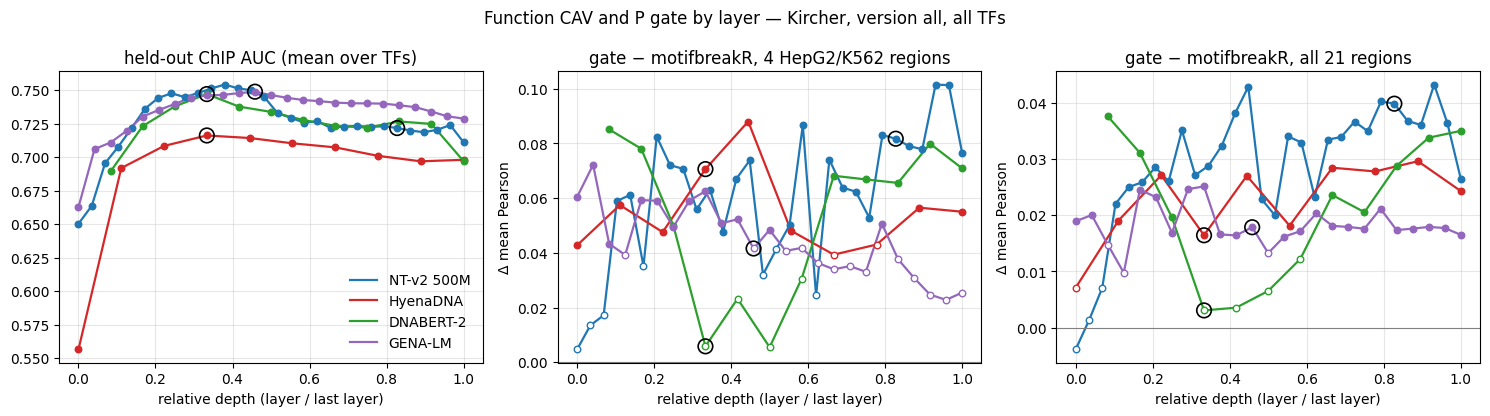

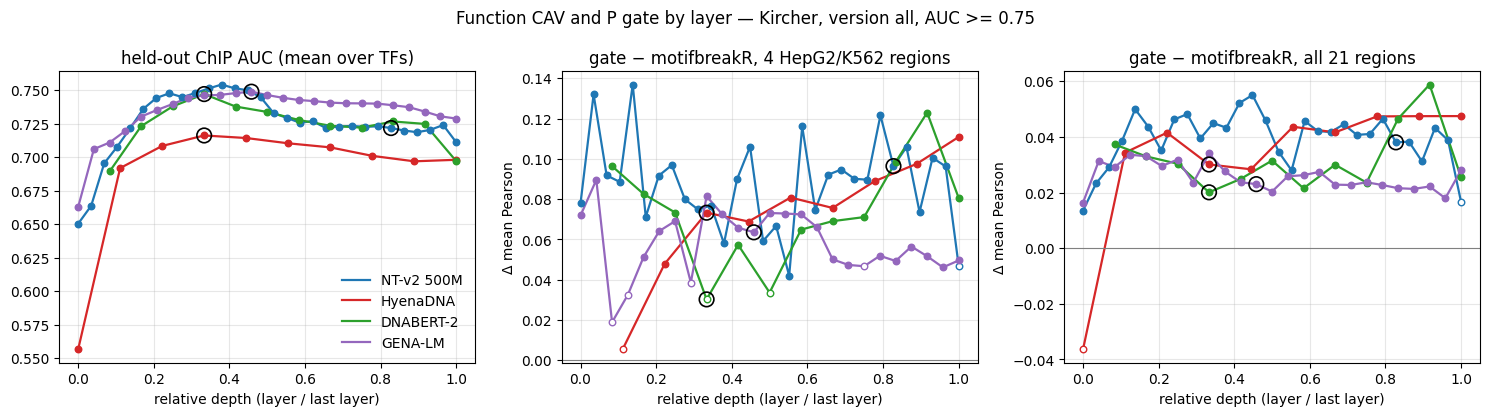

In [4]:
import matplotlib.pyplot as plt
COL = {"nt500m": "#1f77b4", "hyenadna": "#d62728", "dnabert2": "#2ca02c", "genalm": "#9467bd"}
NAME = {"nt500m": "NT-v2 500M", "hyenadna": "HyenaDNA", "dnabert2": "DNABERT-2", "genalm": "GENA-LM"}
for version in VERSIONS:
    for tier, _ in K_TIERS:
        t = LS[(LS.version == version) & (LS.tier == tier)]
        if not len(t):
            continue
        fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
        for model in DONE[version]:
            for k, (col, grp) in enumerate((("mean ChIP AUC", "all regions"), ("gain", "HepG2/K562"), ("gain", "all regions"))):
                u = t[(t.model == model) & (t.regions == grp)].sort_values("depth")
                ax[k].plot(u.depth, u[col], "-", color=COL[model], label=NAME[model], lw=1.6)
                sig = u["p N2"] < 0.05 if col == "gain" else np.ones(len(u), bool)
                ax[k].scatter(u.depth[sig], u[col][sig], color=COL[model], s=22, zorder=3)
                ax[k].scatter(u.depth[~sig], u[col][~sig], facecolor="white", edgecolor=COL[model], s=22, zorder=3)
                o = u[u.layer == OLD_LAYER_OF.get(model, -1)]
                ax[k].scatter(o.depth, o[col], facecolor="none", edgecolor="black", s=110, lw=1.2, zorder=4)
        ax[0].set_title("held-out ChIP AUC (mean over TFs)")
        ax[1].set_title("gate − motifbreakR, 4 HepG2/K562 regions")
        ax[2].set_title("gate − motifbreakR, all 21 regions")
        for a_ in ax:
            a_.set_xlabel("relative depth (layer / last layer)")
            a_.grid(alpha=.3)
        for a_ in ax[1:]:
            a_.axhline(0, color="grey", lw=.8)
            a_.set_ylabel("Δ mean Pearson")
        ax[0].legend(frameon=False)
        fig.suptitle(f"Function CAV and P gate by layer — Kircher, version {version}, {tier}")
        fig.tight_layout()
        fig.savefig(f"{OUT}/layer_sweep_{version}_{tier.replace(' ', '').replace('>=', 'ge')}.png", dpi=160)
        plt.show()

## End

Outputs: `fcav_pool/site_counts.csv`; `fcav_pool/fits_layers/<version>/<model>/`; `layer_sweep/layer_summary.csv`,
`layer_regions.csv` and the figures.